# Synthetic Indian-university data exploration

This notebook provides a formal exploratory analysis of the reproducible synthetic planner dataset. The records are simulated development data, not observations from real students. The purpose is to verify schema, scale, coverage, distributions, relationships, and data-quality constraints before feature extraction.

The unit of academic analysis is an **enrollment**: one student registered for one course offering. Daily wellness and activity tables have different grains and are not interpreted as enrollment rows until they are aggregated with an explicit time rule. Means, medians, quartiles, and rates below describe this generated snapshot only; they are not population estimates and do not establish causality.

## Notebook map and analytical safeguards

1. Load the local manifest and relational CSV tables.
2. Inspect table sizes, columns, missingness, and key uniqueness.
3. Report descriptive statistics using mean, median, standard deviation, quartiles, and range.
4. Visualize outcomes, course structure, attendance, study behaviour, sleep, screen time, and wellbeing.
5. Treat the analysis as quality control for a synthetic generator, not as evidence about Indian university students.

Final outcomes are shown for descriptive inspection only. They must not be used as predictors before the outcome date in the processing or baseline notebooks.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
while not (ROOT / 'src').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

DATA_DIR = ROOT / 'data' / 'raw' / 'synthetic'
from src.features.synthetic_features import load_synthetic_tables

plt.style.use('seaborn-v0_8-whitegrid')
COLORS = plt.cm.viridis(np.linspace(0.12, 0.88, 8))
tables = load_synthetic_tables(DATA_DIR)
manifest = json.loads((DATA_DIR / 'manifest.json').read_text(encoding='utf-8'))
print(f'Repository: {ROOT}')
print(f'Synthetic data directory: {DATA_DIR}')
display(pd.DataFrame([manifest['configuration']]))

Repository: D:\AI PROJECTS\C++\Smart-Study-Planner
Synthetic data directory: D:\AI PROJECTS\C++\Smart-Study-Planner\data\raw\synthetic


,students,terms,weeks_per_term,start_date
0,1000,3,16,2025-07-01


## 1. Relational inventory and scale

The inventory confirms the generated grain and provides the denominator for every later percentage. Parent tables such as `students`, `courses`, and `academic_terms` should remain much smaller than event tables such as `attendance_records`, `daily_wellbeing`, and `study_sessions`. This difference is expected in a normalized planner schema: one student can generate many daily and course-level events.

,table,rows,columns,missing_cells
14,daily_wellbeing,336000,12,0
6,availability,336000,8,0
25,sleep_records,336000,10,0
5,attendance_records,192000,6,0
29,student_topic_state,144000,8,0
31,study_sessions,96000,18,23124
21,planner_recommendations,96000,10,0
7,break_records,59733,8,0
23,recommendation_feedback,57266,7,0
24,resource_interactions,43290,8,16180


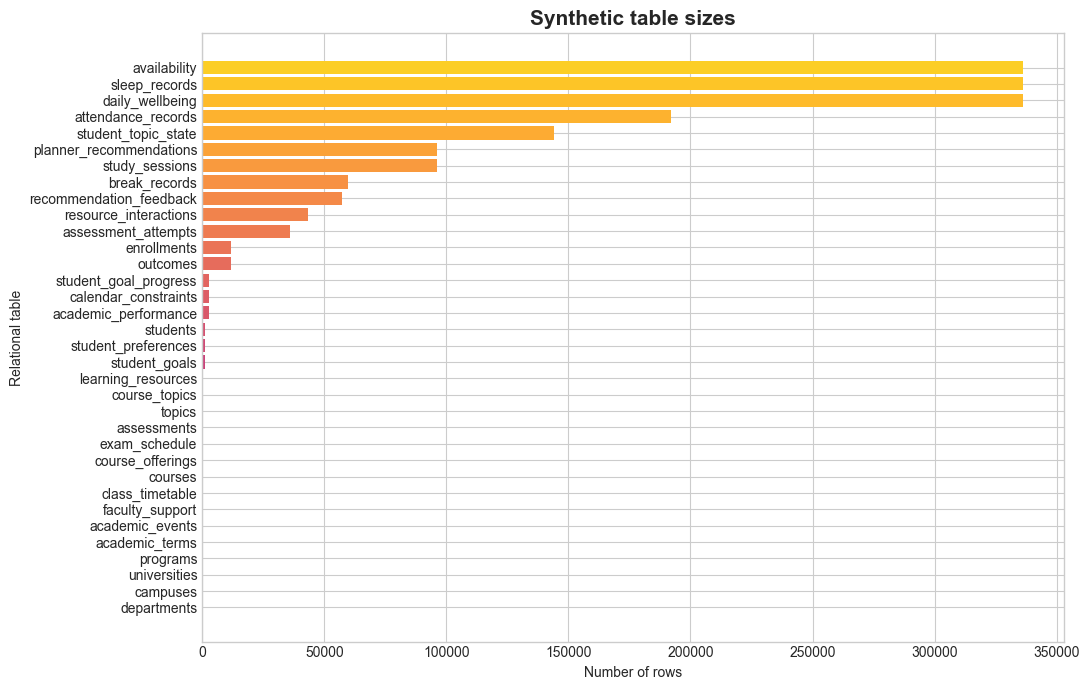

In [2]:
inventory = pd.DataFrame([
    {'table': name, 'rows': len(frame), 'columns': len(frame.columns), 'missing_cells': int(frame.isna().sum().sum())}
    for name, frame in sorted(tables.items())
]).sort_values('rows', ascending=False)
display(inventory)

fig, ax = plt.subplots(figsize=(11, 7))
ordered = inventory.sort_values('rows')
ax.barh(ordered['table'], ordered['rows'], color=plt.cm.plasma(np.linspace(0.15, 0.9, len(ordered))))
ax.set_title('Synthetic table sizes', fontsize=15, weight='bold')
ax.set_xlabel('Number of rows')
ax.set_ylabel('Relational table')
plt.tight_layout()
plt.show()

## 2. Schema, missingness, and identifier checks

Missing values are not automatically errors. For example, a missed study session has no actual start and a partial interaction may have no completion time. The quality check therefore reports missingness for review rather than replacing it with zero. Identifier uniqueness is a structural requirement for reliable joins and prevents duplicated entities from inflating rates.

In [3]:
schema = pd.DataFrame([
    {'table': name, 'column': column, 'dtype': str(dtype), 'missing': int(frame[column].isna().sum()), 'missing_pct': round(frame[column].isna().mean() * 100, 2)}
    for name, frame in sorted(tables.items())
    for column, dtype in frame.dtypes.items()
])
display(schema.query('missing > 0').sort_values(['table', 'missing'], ascending=[True, False]).head(30))

key_checks = []
for name, frame in tables.items():
    candidates = [column for column in frame.columns if column.endswith('_id')]
    for column in candidates:
        key_checks.append({'table': name, 'column': column, 'rows': len(frame), 'unique_values': frame[column].nunique(dropna=False), 'duplicate_values': int(frame[column].duplicated().sum())})
display(pd.DataFrame(key_checks).query('duplicate_values > 0').head(20))
print('The displayed duplicate table is expected to be empty for primary identifiers.')

,table,column,dtype,missing,missing_pct
89,course_topics,recommended_deadline,float64,48,100.00
179,resource_interactions,completed_at,object,8090,18.69
182,resource_interactions,resource_rating,float64,8090,18.69
236,study_sessions,actual_start,object,11562,12.04
248,study_sessions,post_session_mastery,float64,11562,12.04
253,topics,prerequisite_topic_id,object,12,25.00


,table,column,rows,unique_values,duplicate_values
1,academic_events,university_id,9,1,8
3,academic_performance,student_id,3000,1000,2000
4,academic_performance,term_id,3000,3,2997
6,academic_terms,university_id,3,1,2
8,assessment_attempts,assessment_id,36000,36,35964
9,assessment_attempts,enrollment_id,36000,12000,24000
11,assessments,offering_id,36,12,24
13,attendance_records,enrollment_id,192000,12000,180000
15,availability,student_id,336000,1000,335000
19,calendar_constraints,student_id,3000,1000,2000


The displayed duplicate table is expected to be empty for primary identifiers.


## 3. Required descriptive statistics

The mean is the arithmetic average, while the median is the 50th percentile and is less sensitive to unusually long or short observations. Standard deviation describes dispersion around the mean; quartiles and the interquartile range describe the central half without assuming a normal distribution. Reporting all of them is important because activity and time variables are commonly skewed.

In [4]:
numeric_targets = {
    'academic_performance': ['semester_gpa', 'cumulative_gpa'],
    'attendance_records': ['attendance_percentage', 'attendance_gap_to_required'],
    'assessment_attempts': ['marks_obtained'],
    'availability': ['available_hours', 'commute_hours', 'part_time_work_hours'],
    'study_sessions': ['planned_duration_minutes', 'actual_duration_minutes', 'active_study_minutes', 'screen_time_minutes'],
    'sleep_records': ['total_sleep_hours', 'sleep_quality_score', 'nap_minutes'],
    'daily_wellbeing': ['total_screen_minutes', 'total_break_minutes', 'sleep_hours', 'sleep_deficit_hours', 'fatigue_score', 'concentration_score', 'stress_score'],
}
stats = []
for table, columns in numeric_targets.items():
    frame = tables[table]
    for column in columns:
        values = pd.to_numeric(frame[column], errors='coerce').dropna()
        stats.append({'table': table, 'variable': column, 'n': len(values), 'mean': values.mean(), 'median': values.median(), 'std': values.std(), 'min': values.min(), 'q1': values.quantile(.25), 'q3': values.quantile(.75), 'iqr': values.quantile(.75) - values.quantile(.25), 'max': values.max()})
descriptive_statistics = pd.DataFrame(stats).round(2)
display(descriptive_statistics)

,table,variable,n,mean,median,std,min,q1,q3,iqr,max
0,academic_performance,semester_gpa,3000,6.71,6.60,1.46,4.00,5.51,7.91,2.40,10.00
1,academic_performance,cumulative_gpa,3000,6.71,6.63,1.43,4.00,5.50,7.91,2.41,10.00
2,attendance_records,attendance_percentage,192000,80.11,83.33,20.64,0.00,66.67,100.00,33.33,100.00
3,attendance_records,attendance_gap_to_required,192000,5.11,8.33,20.64,-75.00,-8.33,25.00,33.33,25.00
4,assessment_attempts,marks_obtained,36000,87.03,89.52,12.71,39.15,77.04,100.00,22.96,100.00
5,availability,available_hours,336000,2.49,2.41,1.09,0.25,1.65,3.31,1.66,6.79
6,availability,commute_hours,336000,0.66,0.18,0.69,0.10,0.10,1.23,1.13,2.20
7,availability,part_time_work_hours,336000,0.75,0.00,0.97,0.00,0.00,1.50,1.50,3.00
8,study_sessions,planned_duration_minutes,96000,67.52,60.00,16.73,45.00,60.00,75.00,15.00,90.00
9,study_sessions,actual_duration_minutes,96000,49.97,51.00,25.39,0.00,37.00,67.00,30.00,103.00


## 4. Academic structure and outcome distribution

Course type, difficulty, credits, and outcome status are shown because a planner must prioritize work using both academic importance and expected effort. The outcome is a generated endpoint for descriptive inspection. It is not a permissible early-warning feature before the course has ended.

,result_status,count,percent
0,passed,11847,98.72
1,withdrawn,153,1.27


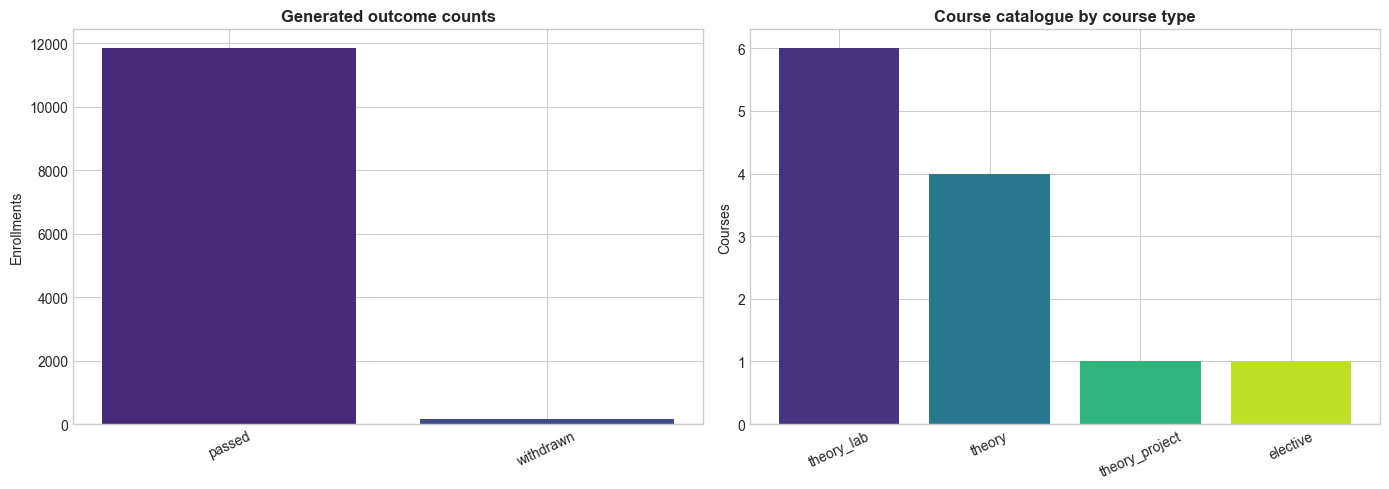

In [5]:
students = tables['students']
courses = tables['courses']
enrollments = tables['enrollments']
offerings = tables['course_offerings']
outcomes = tables['outcomes']
course_outcomes = enrollments.merge(offerings[['offering_id', 'course_id']], on='offering_id').merge(courses[['course_id', 'course_type', 'difficulty', 'credits']], on='course_id').merge(outcomes[['student_id', 'offering_id', 'result_status']], on=['student_id', 'offering_id'])
outcome_counts = outcomes['result_status'].value_counts().rename_axis('result_status').reset_index(name='count')
outcome_counts['percent'] = (outcome_counts['count'] / outcome_counts['count'].sum() * 100).round(2)
display(outcome_counts)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(outcome_counts['result_status'], outcome_counts['count'], color=COLORS[:len(outcome_counts)])
axes[0].set_title('Generated outcome counts', weight='bold')
axes[0].set_ylabel('Enrollments')
axes[0].tick_params(axis='x', rotation=25)
course_counts = courses['course_type'].value_counts()
axes[1].bar(course_counts.index, course_counts.values, color=plt.cm.viridis(np.linspace(.15, .9, len(course_counts))))
axes[1].set_title('Course catalogue by course type', weight='bold')
axes[1].set_ylabel('Courses')
axes[1].tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.show()

## 5. Student context and planner-relevant behaviour

Residence and employment are contextual constraints, not recommendations targets. Available hours, commute, work, sleep, screen exposure, breaks, and concentration are included because the smart study planner must construct feasible schedules rather than simply rank students by academic score. The plots are used to inspect variation and boundary behaviour.

,variable,category,count,percent
0,residence_type,hosteller,500,50.0
1,residence_type,day_scholar,500,50.0
2,employment_status,none,500,50.0
3,employment_status,part_time,500,50.0


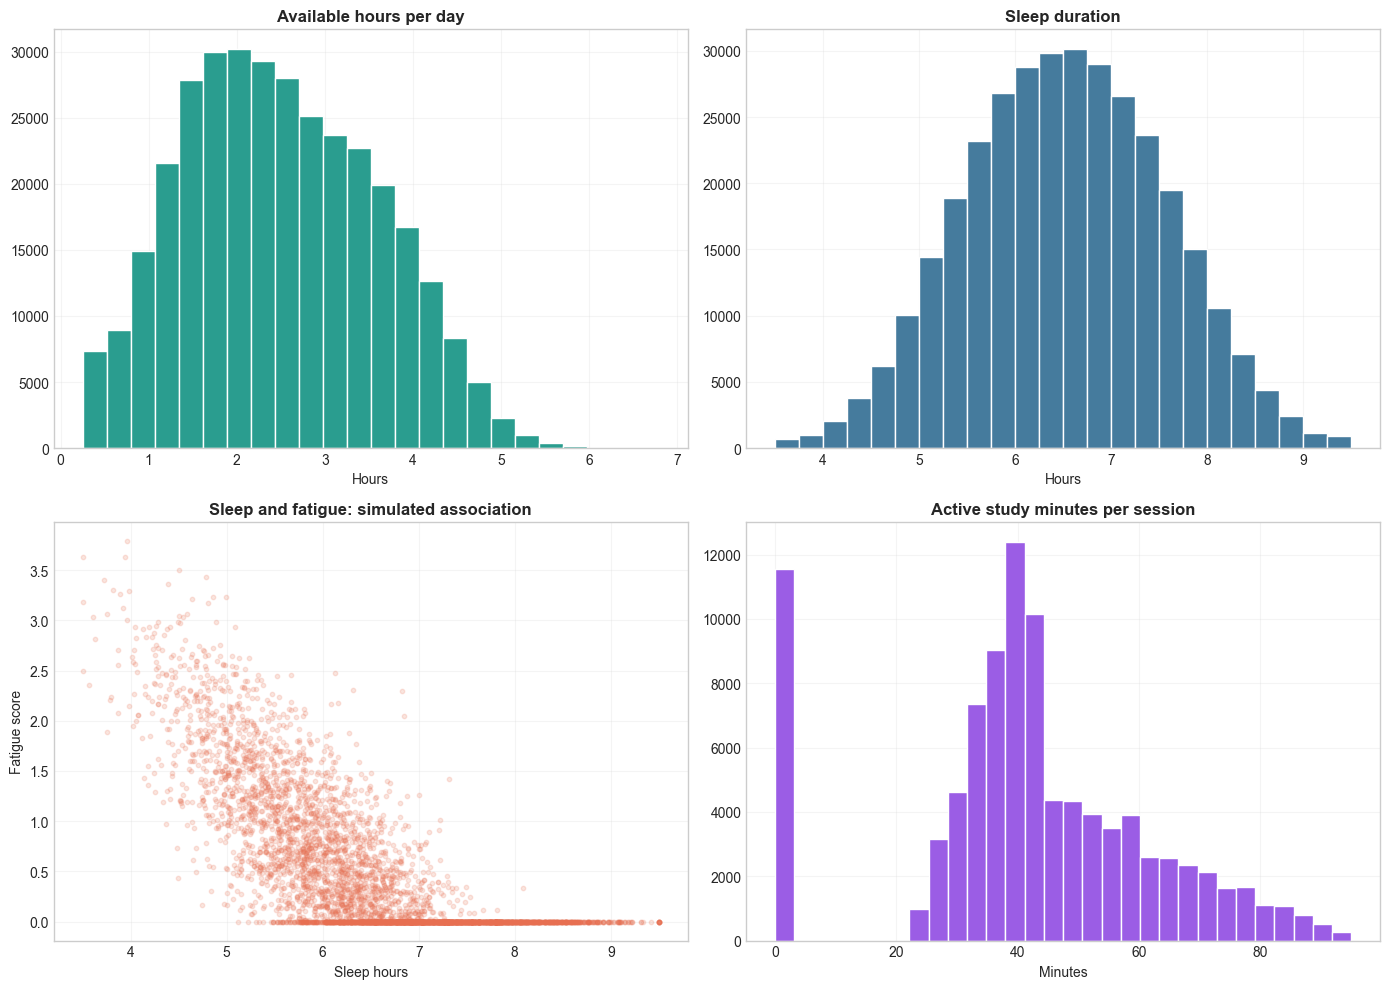

,variable,mean,median,std,mean_minus_median
0,available_hours,2.49,2.41,1.09,0.08
1,sleep_hours,6.52,6.51,1.03,0.01
2,fatigue_score,0.47,0.00,0.69,0.47
3,active_study_minutes,41.57,41.00,20.90,0.57


The mean-minus-median column quantifies skew direction: positive values indicate that longer observations pull the mean above the typical median record.


In [6]:
context = pd.concat([
    students['residence_type'].value_counts().rename('count').to_frame().assign(variable='residence_type', category=lambda x: x.index),
    students['employment_status'].value_counts().rename('count').to_frame().assign(variable='employment_status', category=lambda x: x.index),
], ignore_index=True)
context['percent'] = (context['count'] / len(students) * 100).round(2)
display(context[['variable', 'category', 'count', 'percent']])

wellbeing = tables['daily_wellbeing']
availability = tables['availability']
sessions = tables['study_sessions']
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes[0, 0].hist(availability['available_hours'], bins=24, color='#2a9d8f', edgecolor='white')
axes[0, 0].set_title('Available hours per day', weight='bold')
axes[0, 0].set_xlabel('Hours')
axes[0, 1].hist(wellbeing['sleep_hours'], bins=24, color='#457b9d', edgecolor='white')
axes[0, 1].set_title('Sleep duration', weight='bold')
axes[0, 1].set_xlabel('Hours')
axes[1, 0].scatter(wellbeing['sleep_hours'].sample(min(5000, len(wellbeing)), random_state=42), wellbeing['fatigue_score'].sample(min(5000, len(wellbeing)), random_state=42), alpha=.18, color='#e76f51', s=10)
axes[1, 0].set_title('Sleep and fatigue: simulated association', weight='bold')
axes[1, 0].set_xlabel('Sleep hours')
axes[1, 0].set_ylabel('Fatigue score')
axes[1, 1].hist(sessions['active_study_minutes'], bins=30, color='#9b5de5', edgecolor='white')
axes[1, 1].set_title('Active study minutes per session', weight='bold')
axes[1, 1].set_xlabel('Minutes')
for ax in axes.ravel(): ax.grid(alpha=.2)
plt.tight_layout()
plt.show()
graph_statistics = pd.DataFrame({
    'variable': ['available_hours', 'sleep_hours', 'fatigue_score', 'active_study_minutes'],
    'mean': [availability['available_hours'].mean(), wellbeing['sleep_hours'].mean(), wellbeing['fatigue_score'].mean(), sessions['active_study_minutes'].mean()],
    'median': [availability['available_hours'].median(), wellbeing['sleep_hours'].median(), wellbeing['fatigue_score'].median(), sessions['active_study_minutes'].median()],
    'std': [availability['available_hours'].std(), wellbeing['sleep_hours'].std(), wellbeing['fatigue_score'].std(), sessions['active_study_minutes'].std()],
})
graph_statistics['mean_minus_median'] = graph_statistics['mean'] - graph_statistics['median']
display(graph_statistics.round(2))
print('The mean-minus-median column quantifies skew direction: positive values indicate that longer observations pull the mean above the typical median record.')

### Interpretation

The descriptive tables and plots should be read as generator diagnostics. A broad distribution is desirable for testing scheduling logic and model robustness, but a broad distribution alone does not validate realism.

The graph statistics table reports the mean, median, standard deviation, and mean-minus-median value for each plotted variable. A positive difference indicates right-skew: a smaller number of larger observations pulls the mean above the typical median record. This distinction matters for a planner because a mean-based schedule can overestimate what is available to a typical student when time distributions are skewed.

The sleep/fatigue scatter is labelled as a simulated association. The generator intentionally correlates several fields through latent profile assumptions, so the visual relationship is useful for testing graphing and planner logic but must not be presented as a causal finding or as an estimate for a real university.